In [7]:
import pandas as pd

variables = [
    # Patient Demographics
    ("race", "Feature", "Categorical", "Patient race"),
    ("gender", "Feature", "Categorical", "Patient gender"),
    ("age", "Feature", "Categorical", "Patient age grouped into 10-year intervals"),

    # Hospitalization Information
    ("admission_type_id", "Feature", "Categorical", "Type of hospital admission"),
    ("discharge_disposition_id", "Feature", "Categorical", "Patient discharge disposition"),
    ("admission_source_id", "Feature", "Categorical", "Source of hospital admission"),
    ("time_in_hospital", "Feature", "Integer", "Number of days spent in the hospital"),
    ("medical_specialty", "Feature", "Categorical", "Specialty of the admitting physician"),

    # Medical Procedures
    ("num_lab_procedures", "Feature", "Integer", "Number of laboratory tests performed"),
    ("num_procedures", "Feature", "Integer", "Number of non-laboratory procedures performed"),
    ("num_medications", "Feature", "Integer", "Number of distinct medications administered"),

    # Previous Healthcare Visits
    ("number_outpatient", "Feature", "Integer", "Number of outpatient visits in the previous year"),
    ("number_emergency", "Feature", "Integer", "Number of emergency visits in the previous year"),
    ("number_inpatient", "Feature", "Integer", "Number of inpatient visits in the previous year"),

    # Diagnoses
    ("diag_1", "Feature", "Categorical", "Primary diagnosis (ICD-9 code)"),
    ("diag_2", "Feature", "Categorical", "Secondary diagnosis (ICD-9 code)"),
    ("diag_3", "Feature", "Categorical", "Additional secondary diagnosis (ICD-9 code)"),
    ("number_diagnoses", "Feature", "Integer", "Total number of diagnoses recorded"),

    # Diabetes Medications
    ("metformin", "Feature", "Categorical", "Metformin prescription or dosage change"),
    ("repaglinide", "Feature", "Categorical", "Repaglinide prescription or dosage change"),
    ("nateglinide", "Feature", "Categorical", "Nateglinide prescription or dosage change"),
    ("chlorpropamide", "Feature", "Categorical", "Chlorpropamide prescription or dosage change"),
    ("glimepiride", "Feature", "Categorical", "Glimepiride prescription or dosage change"),
    ("glipizide", "Feature", "Categorical", "Glipizide prescription or dosage change"),
    ("glyburide", "Feature", "Categorical", "Glyburide prescription or dosage change"),
    ("pioglitazone", "Feature", "Categorical", "Pioglitazone prescription or dosage change"),
    ("rosiglitazone", "Feature", "Categorical", "Rosiglitazone prescription or dosage change"),
    ("acarbose", "Feature", "Categorical", "Acarbose prescription or dosage change"),
    ("miglitol", "Feature", "Categorical", "Miglitol prescription or dosage change"),
    ("tolazamide", "Feature", "Categorical", "Tolazamide prescription or dosage change"),
    ("insulin", "Feature", "Categorical", "Insulin prescription or dosage change"),
    ("glyburide-metformin", "Feature", "Categorical", "Glyburide and metformin combination medication"),

    # Treatment Information
    ("change", "Feature", "Categorical", "Indicates whether diabetes medication was changed"),
    ("diabetesMed", "Feature", "Categorical", "Indicates whether diabetes medication was prescribed"),

    # Target Variable
    ("readmitted", "Target", "Categorical", "Hospital readmission (<30 days, >30 days, or No)")
]

# Create DataFrame
variable_df = pd.DataFrame(
    variables,
    columns=["Variable", "Role", "Type", "Description"]
)

display(variable_df)

,Variable,Role,Type,Description
0,race,Feature,Categorical,Patient race
1,gender,Feature,Categorical,Patient gender
2,age,Feature,Categorical,Patient age grouped into 10-year intervals
3,admission_type_id,Feature,Categorical,Type of hospital admission
4,discharge_disposition_id,Feature,Categorical,Patient discharge disposition
5,admission_source_id,Feature,Categorical,Source of hospital admission
6,time_in_hospital,Feature,Integer,Number of days spent in the hospital
7,medical_specialty,Feature,Categorical,Specialty of the admitting physician
8,num_lab_procedures,Feature,Integer,Number of laboratory tests performed
9,num_procedures,Feature,Integer,Number of non-laboratory procedures performed


# Variable Table (Description)
In this first part of the notebook, we created the variable table using the Variable table from the ICS website as source data. This variable table will help us throught the EDA analysis to verify what each variable means and what do their numbers represent for our analysis.

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Loading the CSV from the cleaning-of-the-database branch in the Final project github
url = "https://raw.githubusercontent.com/mvillarreal-usd/FinalTeamProjectAAI-500/refs/heads/cleaning-of-the-database/cleaned_database.csv"
# Putting the database into a pandas Dataframe
df = pd.read_csv(url)

# Displaying the first 5 rows of the dataset to verify it got pulled correctly
display(df.head())


,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,medical_specialty,num_lab_procedures,num_procedures,...,pioglitazone,rosiglitazone,acarbose,miglitol,tolazamide,insulin,glyburide-metformin,change,diabetesMed,readmitted
0,Caucasian,Female,[0-10),6,25,1,1,Pediatrics-Endocrinology,41,0,...,No,No,No,No,No,No,No,No,No,NO
1,Caucasian,Female,[10-20),1,1,7,3,NaN,59,0,...,No,No,No,No,No,Up,No,Ch,Yes,>30
2,AfricanAmerican,Female,[20-30),1,1,7,2,NaN,11,5,...,No,No,No,No,No,No,No,No,Yes,NO
3,Caucasian,Male,[30-40),1,1,7,2,NaN,44,1,...,No,No,No,No,No,Up,No,Ch,Yes,NO
4,Caucasian,Male,[40-50),1,1,7,1,NaN,51,0,...,No,No,No,No,No,Steady,No,Ch,Yes,NO


# First Observations.
The dataset contains information about hospital patients, demographics, hospital admissions, medical procedures, diagnoses, and medications. These variables can help us explore potential relationships between patient characteristics and hospital readmissions.

This variables will help us further down the line to identify the proper model to be used for this project. We can categorize these variables as follows:


*   Demographic Variables: race, gender, and age.
*   Hospitalization Variables: time_in_hospital, admission_type_id, and discharge_disposition_id.
*   Medical Variables: num_lab_procedures, num_procedures, num_medications, and number_diagnoses.
*   Previous Healthcare Utilization: number_outpatient, number_emergency, and number_inpatient.



,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,101766.00,101766.00,101766.00,101766.00,101766.00,101766.00,101766.00,101766.00
mean,4.40,43.10,1.34,16.02,0.37,0.20,0.64,7.42
std,2.99,19.67,1.71,8.13,1.27,0.93,1.26,1.93
min,1.00,1.00,0.00,1.00,0.00,0.00,0.00,1.00
25%,2.00,31.00,0.00,10.00,0.00,0.00,0.00,6.00
50%,4.00,44.00,1.00,15.00,0.00,0.00,0.00,8.00
75%,6.00,57.00,2.00,20.00,0.00,0.00,1.00,9.00
max,14.00,132.00,6.00,81.00,42.00,76.00,21.00,16.00


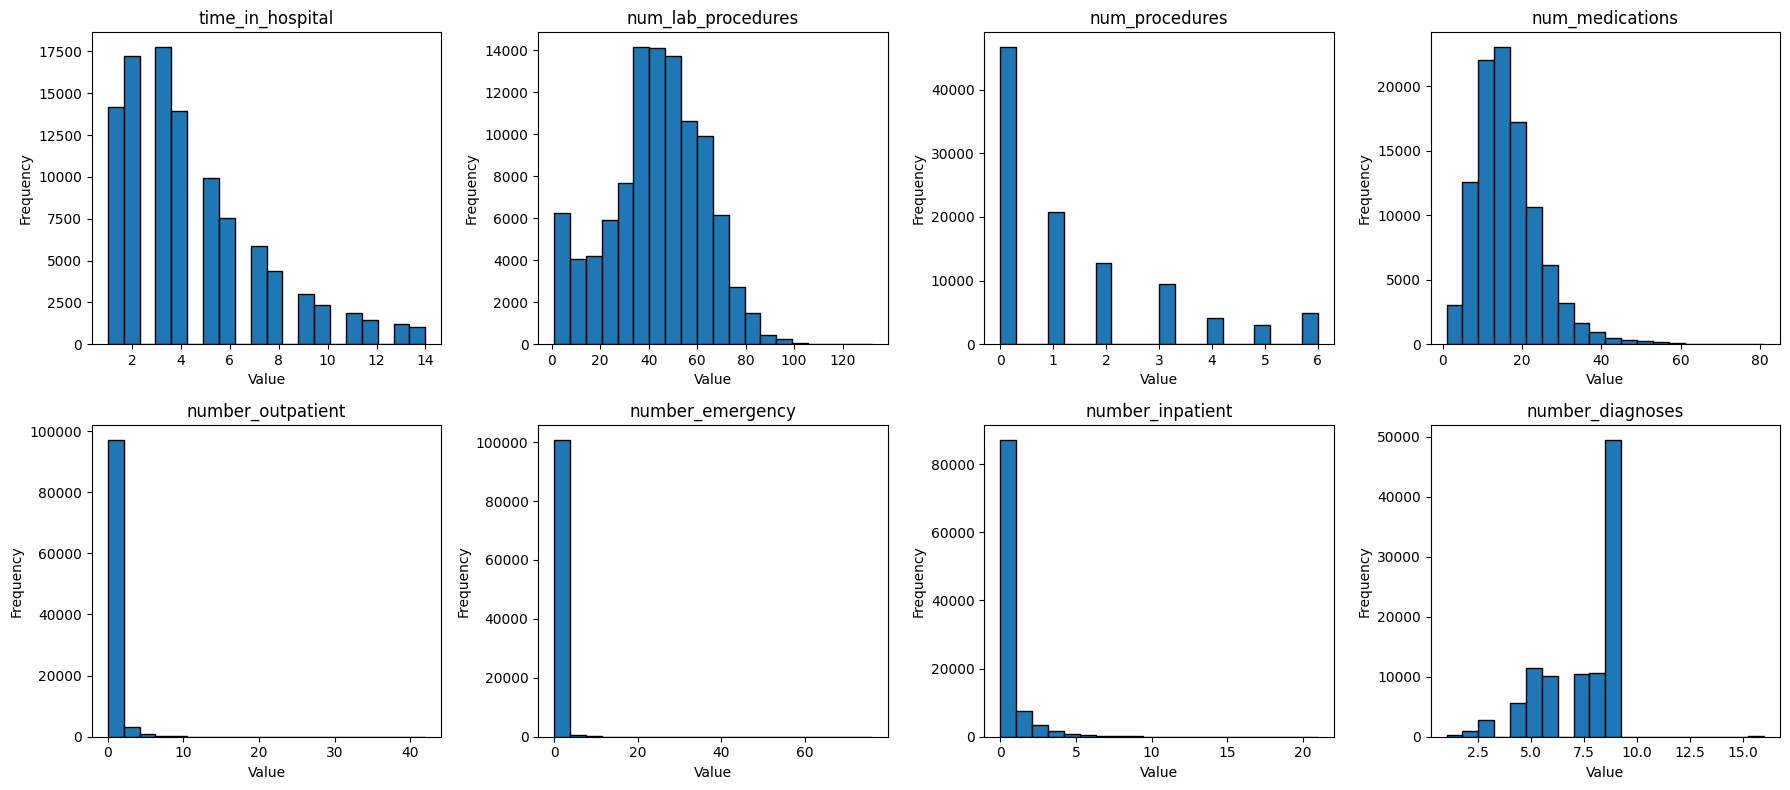

In [3]:
# Select the numerical variables for the Exploratory analysis to create a descriptive statistics to give us relevant information.
numerical_columns = [
    'time_in_hospital',
    'num_lab_procedures',
    'num_procedures',
    'num_medications',
    'number_outpatient',
    'number_emergency',
    'number_inpatient',
    'number_diagnoses'
]

# Descriptive statistics
display(df[numerical_columns].describe().round(2))

# Creating 8 plots to visually the descriptive statistics of the 8 numerical variables that we are interested in.
# Dividing the grid for the plots into 2 rows and four columns to show the graphics in a organized way.
fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for ax, column in zip(axes.flatten(), numerical_columns):
    ax.hist(df[column].dropna(), bins=20, edgecolor='black')
    ax.set_title(column)
    ax.set_xlabel('Value')
    ax.set_ylabel('Frequency')

# Displaying the plots.
plt.tight_layout()
plt.show()

# Numerical Variables Interpretation

Most numerical variables show a right-skewed distribution, for example:


*   time_in_hospital
*   num_medications
*   number_outpatient
*   number_emergency
*   number_inpatient

Patients spent an average of **4.40** days in the hospital and received approximately **16** medications during their stay. The number of laboratory procedures has a relatively balanced distribution, with a mean of **43.10** and a median of **44**.

The number of diagnoses shows a slightly left-skewed distribution, with a mean of **7.42** and a median of 8.

One particularly interesting finding was that the previous inpatient visits have a maximum of **21**, compared with a median of zero. Meaning, this could be a good variable to investigate comparing patients who were readmitted within 30 days against those who were not.

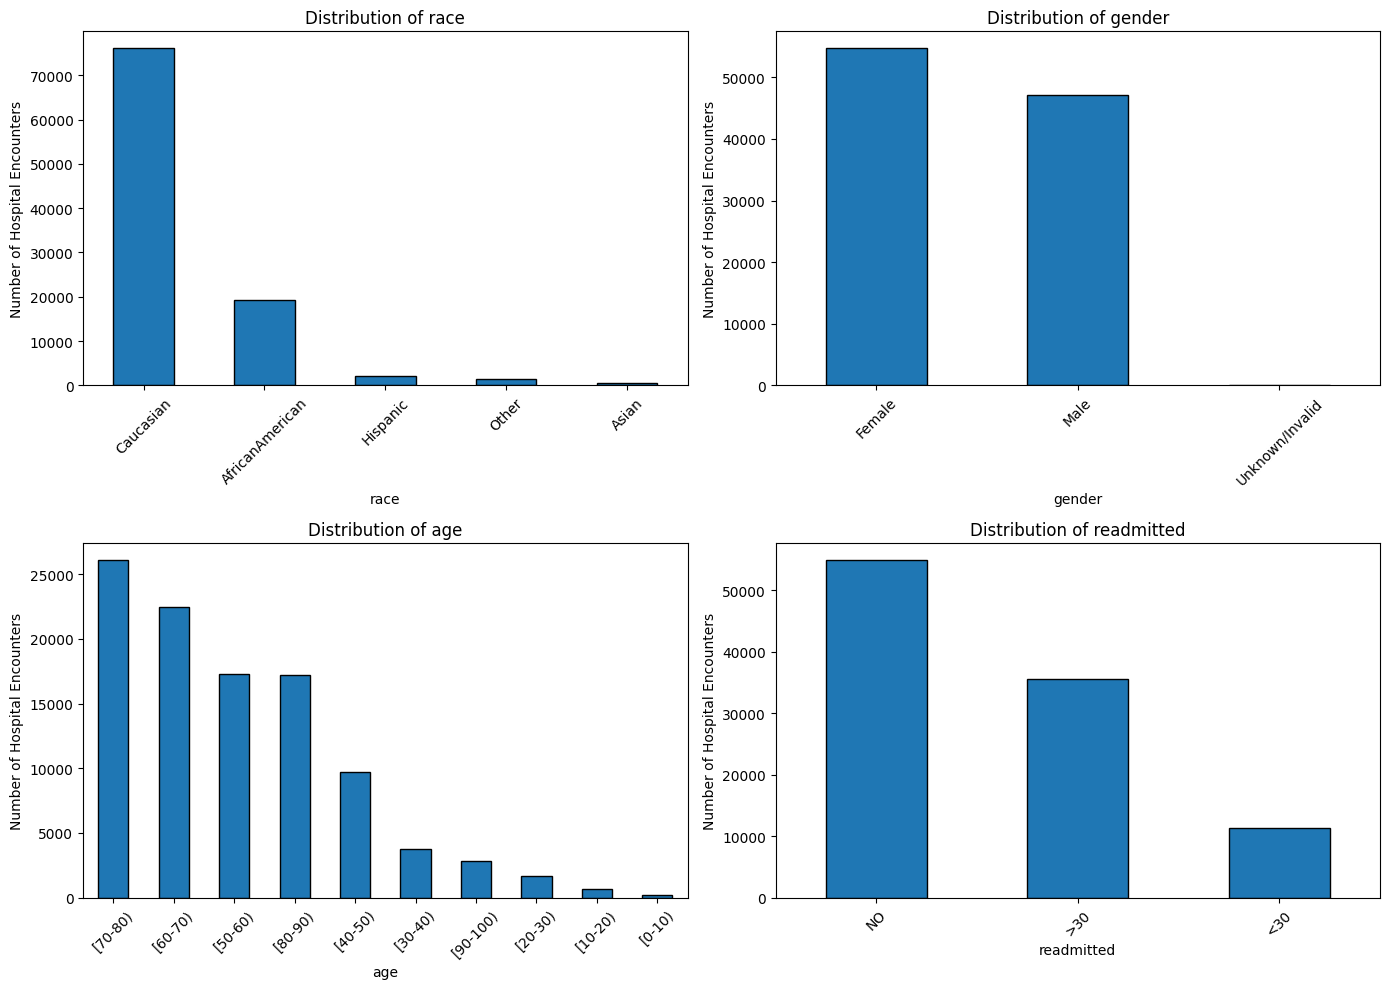

In [9]:
# Selected categorical variables for visualization on EDA
selected_categorical = [
    'race',
    'gender',
    'age',
    'readmitted'
]

# Creating 4 plots, 2 per row and 2 columns
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, column in zip(axes.flatten(), selected_categorical):
    df[column].value_counts().plot(
        kind='bar',
        ax=ax,
        edgecolor='black'
    )

    ax.set_title(f'Distribution of {column}')
    ax.set_xlabel(column)
    ax.set_ylabel('Number of Hospital Encounters')
    ax.tick_params(axis='x', rotation=45)

# Plotting
plt.tight_layout()
plt.show()
plt.show()

# Categorical Variables Interpretation

The categorical distributions show that most hospital encounters involve Caucasian patients, followed by African American patients, while the other racial groups have much lower representation. Female patients slightly outnumber male patients, and most encounters involve patients between 50 and 90 years old, particularly those aged 70–80. Regarding hospital readmissions, more than half of the encounters have no recorded readmission, followed by readmissions after 30 days, while readmissions within 30 days are the least common.

In [10]:
# Readmission distribution and actual number data
readmission_counts = df['readmitted'].value_counts()
readmission_percentages = df['readmitted'].value_counts(normalize=True) * 100

readmission_summary = pd.DataFrame({
    'Count': readmission_counts,
    'Percentage (%)': readmission_percentages
})

display(readmission_summary.round(2))

,Count,Percentage (%)
readmitted,,
NO,54864,53.91
>30,35545,34.93
<30,11357,11.16


# Readmission (Target Variable)

Since we are interested in Readmission as our target variable with this dataset, its important to get the actual values for this variable instead of just a visualization. Therefore, this section of the code gives us the summary of information needed for this variable.

**Github Incorporation**
Now that we have everything we need for the EDA, we can start to upload this notebook automatically into the Final project github, so everytime this notebook gets updated it can replace the previous document.

In [ ]:
import requests
import base64
import json
from urllib.parse import quote
from google.colab import userdata, _message


# ============================================================
# STEP 1 - GitHub Configuration
# ============================================================

token = userdata.get("FinalTeamProject")

if not token:
    raise ValueError("GITHUB_TOKEN not found in Colab Secrets.")

headers = {
    "Authorization": f"Bearer {token}",
    "Accept": "application/vnd.github+json",
    "X-GitHub-Api-Version": "2022-11-28"
}

owner = "mvillarreal-usd"
repo = "FinalTeamProjectAAI-500"

source_branch = "main"
new_branch = "EDA-analysis"

api_url = f"https://api.github.com/repos/{owner}/{repo}"


# ============================================================
# STEP 2 - Check or Create GitHub Branch
# ============================================================

branch_url = (
    f"{api_url}/git/ref/heads/"
    f"{quote(new_branch, safe='')}"
)

response = requests.get(branch_url, headers=headers)

if response.status_code == 200:
    print(f"Branch '{new_branch}' already exists.")
    print("Using existing branch.")

elif response.status_code == 404:
    print(f"Branch '{new_branch}' not found.")
    print(f"Creating branch from '{source_branch}'...")

    source_url = (
        f"{api_url}/git/ref/heads/{source_branch}"
    )

    source_response = requests.get(
        source_url,
        headers=headers
    )
    source_response.raise_for_status()

    sha = source_response.json()["object"]["sha"]

    create_url = f"{api_url}/git/refs"

    branch_data = {
        "ref": f"refs/heads/{new_branch}",
        "sha": sha
    }

    create_response = requests.post(
        create_url,
        headers=headers,
        json=branch_data
    )

    if create_response.status_code == 201:
        print(f"Branch '{new_branch}' created successfully!")

    elif create_response.status_code == 422:
        check = requests.get(branch_url, headers=headers)
        check.raise_for_status()
        print(f"Branch '{new_branch}' already exists.")

    else:
        create_response.raise_for_status()

else:
    response.raise_for_status()


# ============================================================
# STEP 3 - Retrieve Current Google Colab Notebook
# ============================================================

print("\nRetrieving current Google Colab notebook...")

notebook_info = _message.blocking_request(
    "get_ipynb",
    timeout_sec=60
)

notebook_content = notebook_info["ipynb"]

# Attempt to retrieve the notebook's actual name
notebook_name = "EDA_CleanedDatabase_FinalProjectAAI500.ipynb"

print(f"Notebook: {notebook_name}")


# ============================================================
# STEP 4 - Encode Notebook for GitHub
# ============================================================

notebook_json = json.dumps(
    notebook_content,
    ensure_ascii=False,
    indent=1
)

encoded_content = base64.b64encode(
    notebook_json.encode("utf-8")
).decode("utf-8")


# ============================================================
# STEP 5 - Check Whether Notebook Already Exists
# ============================================================

file_path = quote(notebook_name, safe="")

file_url = f"{api_url}/contents/{file_path}"

check = requests.get(
    file_url,
    headers=headers,
    params={"ref": new_branch}
)

upload_data = {
    "message": f"Add EDA notebook: {notebook_name}",
    "content": encoded_content,
    "branch": new_branch
}

if check.status_code == 200:

    if check.json().get("type") != "file":
        raise ValueError("The GitHub path exists but is not a file.")

    upload_data["sha"] = check.json()["sha"]
    upload_data["message"] = (
        f"Update EDA notebook: {notebook_name}"
    )

    print("\nExisting notebook found.")
    print("Replacing with latest version...")

elif check.status_code == 404:

    print("\nNotebook does not exist.")
    print("Creating new notebook...")

else:
    check.raise_for_status()


# ============================================================
# STEP 6 - Upload Notebook to GitHub
# ============================================================

response = requests.put(
    file_url,
    headers=headers,
    json=upload_data
)

response.raise_for_status()

if response.status_code == 201:
    print("\nNew notebook created successfully!")

elif response.status_code == 200:
    print("\nExisting notebook updated successfully!")

print("\nGitHub Upload Summary")
print("------------------------------")
print(f"Repository: {repo}")
print(f"Branch: {new_branch}")
print(f"Notebook: {notebook_name}")
print(f"Commit SHA: {response.json()['commit']['sha']}")
print(f"GitHub URL: {response.json()['content']['html_url']}")

Branch 'EDA-analysis' not found.
Creating branch from 'main'...
